# 多模态 AIGC 图像生成 02：图像生成算法

本篇对应讲义《02-图像生成.pdf》，按原资料介绍图像生成的发展路线和代表性模型：

- VAE、GAN 与扩散模型三类图像生成算法；
- 扩散模型的前向加噪、反向去噪和典型应用；
- CLIP 的跨模态预训练方式，以及 DALL·E、Imagen、Stable Diffusion 等代表性系统。

讲义中的宣传页和结束页已省略。

## 一、图像生成算法的演进

讲义按时间顺序列出三类重要算法：

| 时间 | 算法 | 讲义中的定位 |
| --- | --- | --- |
| 2014 | 变分自编码器（VAE） | 用概率方式描述潜在空间，在数据生成方面具有应用价值 |
| 2014 | 生成对抗网络（GAN） | 通过生成器和判别器的零和博弈学习生成数据 |
| 2015 | 扩散模型 | 先向数据逐步加噪，再学习逆扩散过程从噪声构建样本 |

扩散模型最初用于去除图像噪声；随着降噪训练越来越充分，输入纯噪声也可以生成逼真的图像。

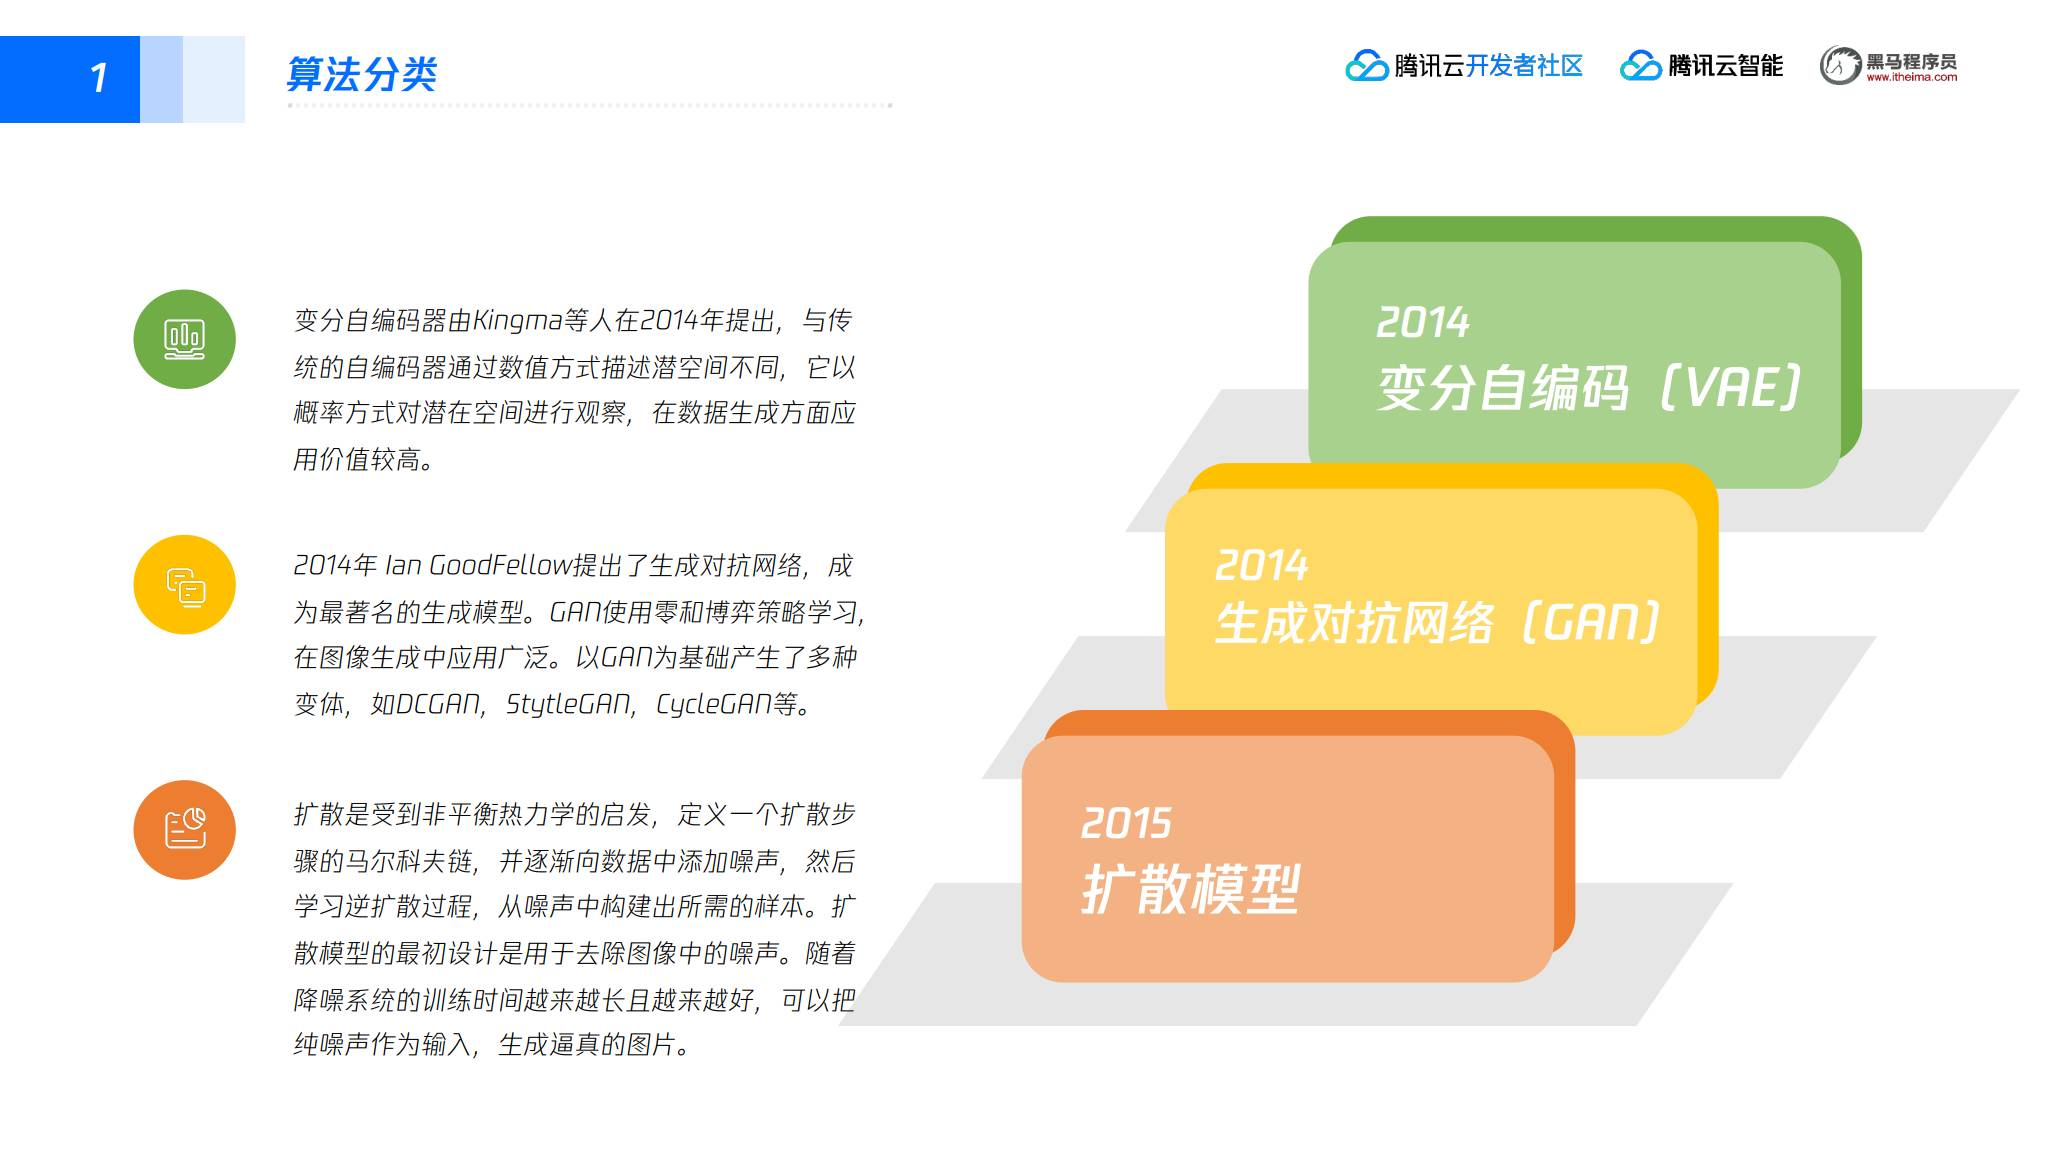

## 二、变分自编码器 VAE

VAE 是一种深度生成模型，核心是用**概率分布描述潜在空间**。它由编码器和解码器组成：

1. 编码器把高维图像数据转换为潜在空间中的概率分布；
2. 从概率分布中采样潜在特征；
3. 解码器根据采样结果重建并生成新数据。

与传统自编码器直接用数值表示潜在特征不同，VAE 允许在潜在分布中采样。讲义以人脸图像为例，潜在特征可以对应微笑、肤色、性别等不同因素，解码器再根据这些特征生成图像。

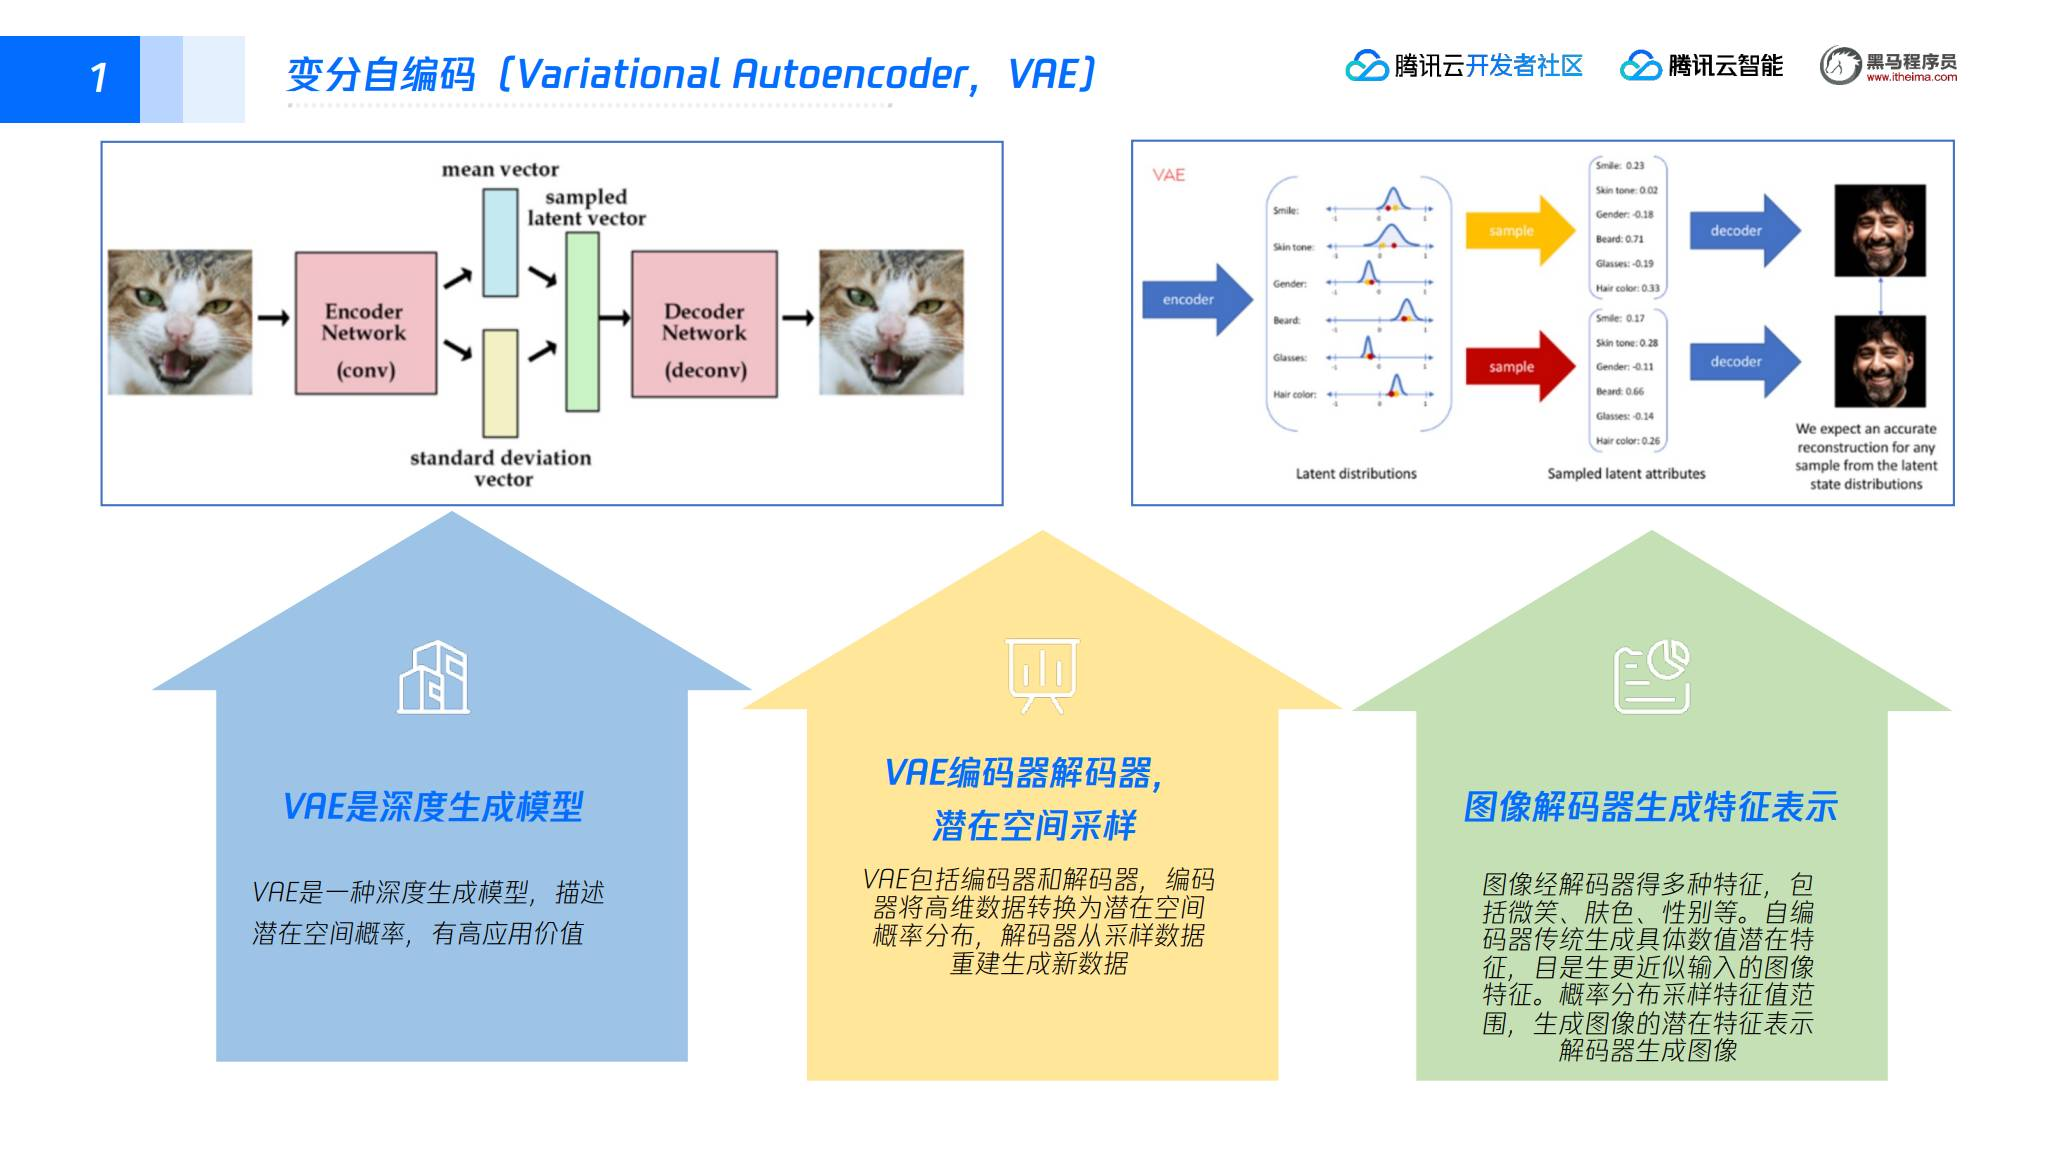

## 三、生成对抗网络 GAN

GAN 由 Ian Goodfellow 于 2014 年提出。它包含两个相互对抗的模型：

- **生成器（Generator）**：输入一组向量，按照特定分布随机生成数据；生成的数据作为判别器的负样本。
- **判别器（Discriminator）**：用真实数据和生成数据训练二分类模型，输出输入为真实数据的概率。

训练过程中，生成器不断学习生成更合理的数据，判别器不断提高区分真实数据与生成数据的能力。讲义指出，GAN 广泛应用于图像生成，并衍生出 DCGAN、StyleGAN、CycleGAN 等变体。典型应用包括人脸替换、卡通头像、图像超分辨率重建和风格迁移。

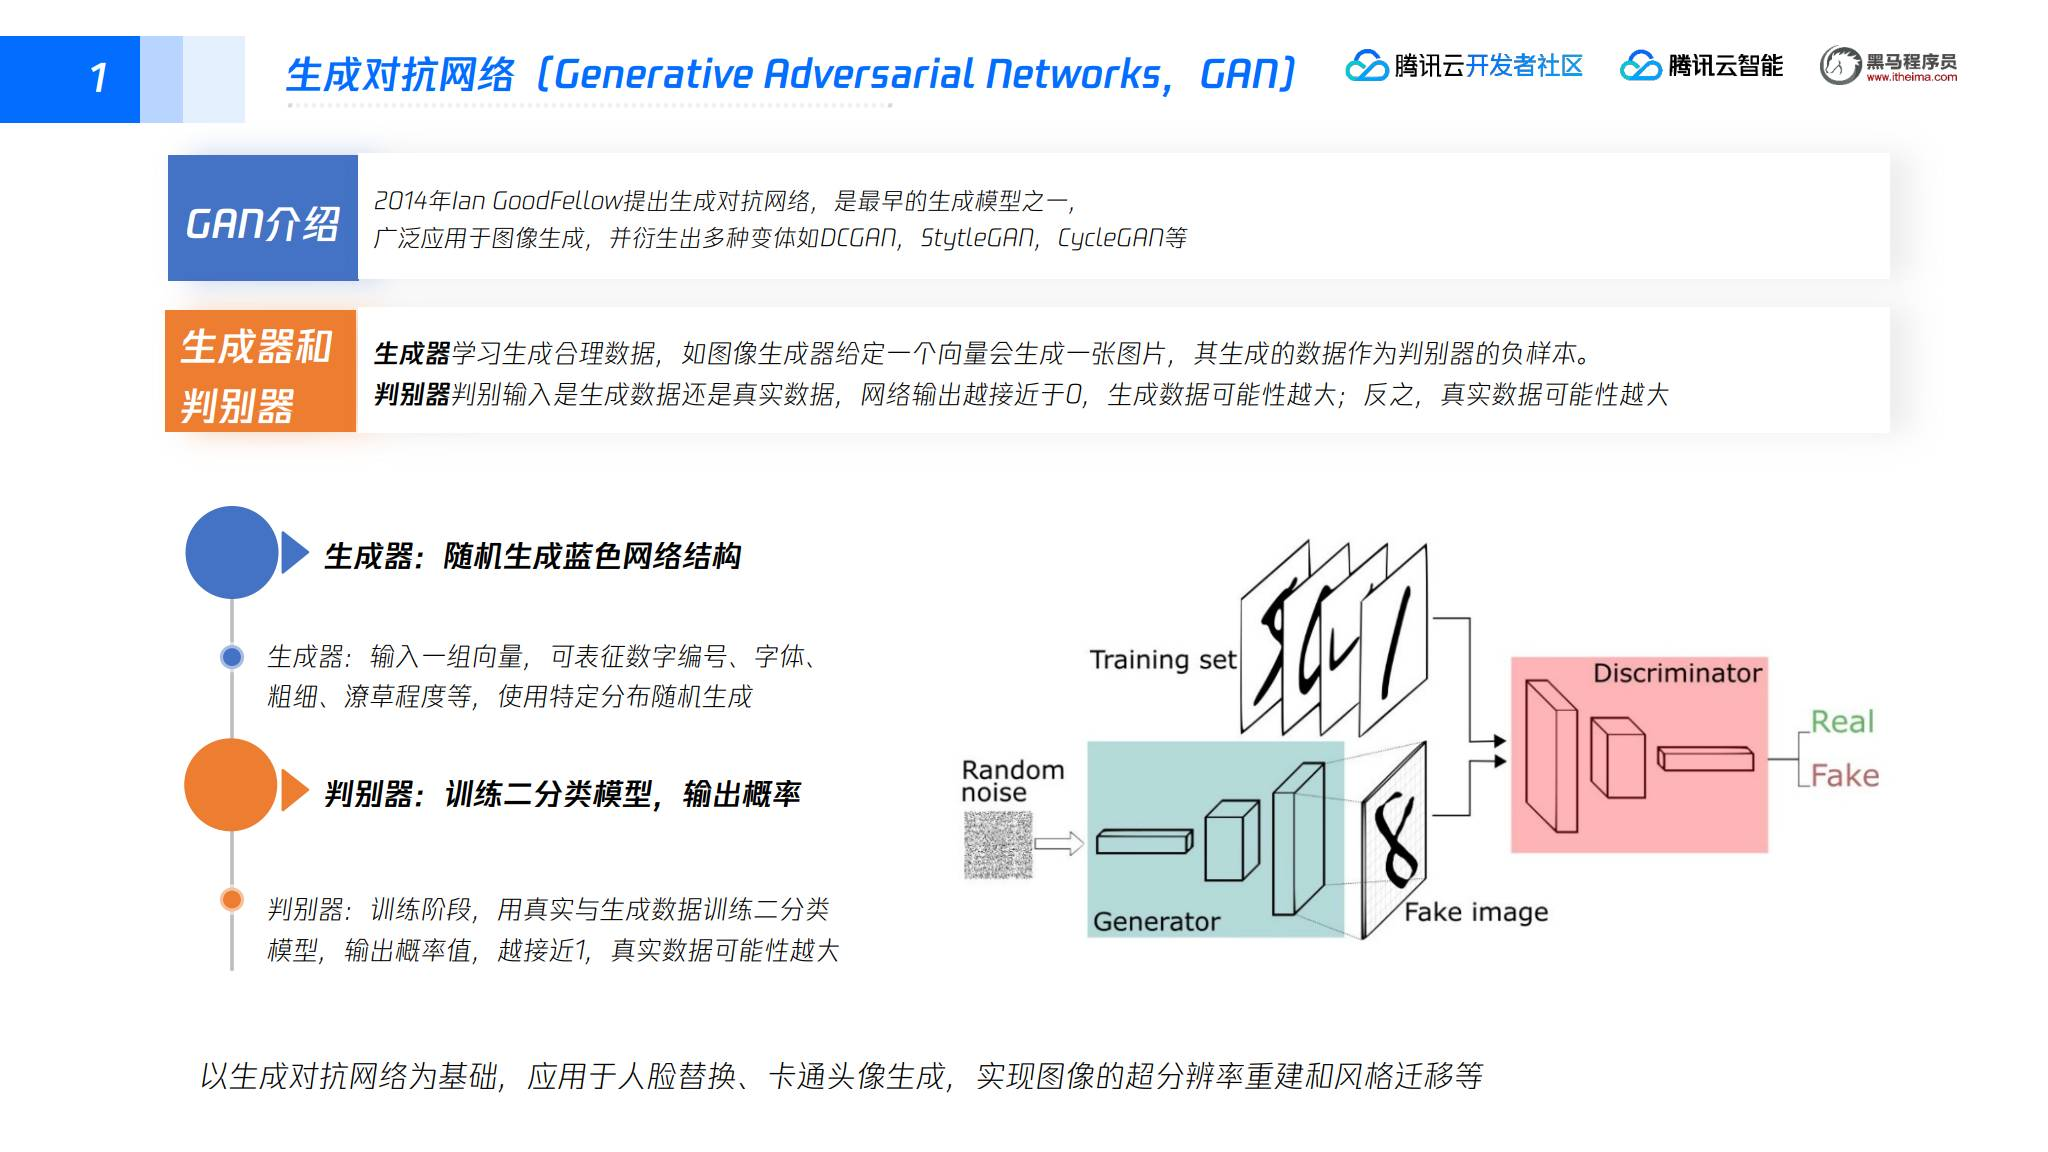

## 四、扩散模型

扩散模型受到非平衡热力学启发，把扩散过程定义为一个马尔可夫链，并学习从噪声中恢复数据。它包含两个方向相反的过程：

### 1. 前向扩散过程

从原始图像开始，逐步向图像中加入噪声。随着时间步增加，图像逐渐被噪声污染，最终接近完全随机的高斯噪声。

### 2. 反向去噪过程

从高斯噪声开始，在每个时间步预测并去除一部分噪声，逐步恢复清晰信号，得到原始图像或其变种。

这种“先加噪、再学习逆过程”的方式，最初用于去噪；当模型的降噪能力足够强时，就可以把纯噪声作为输入来生成图像。

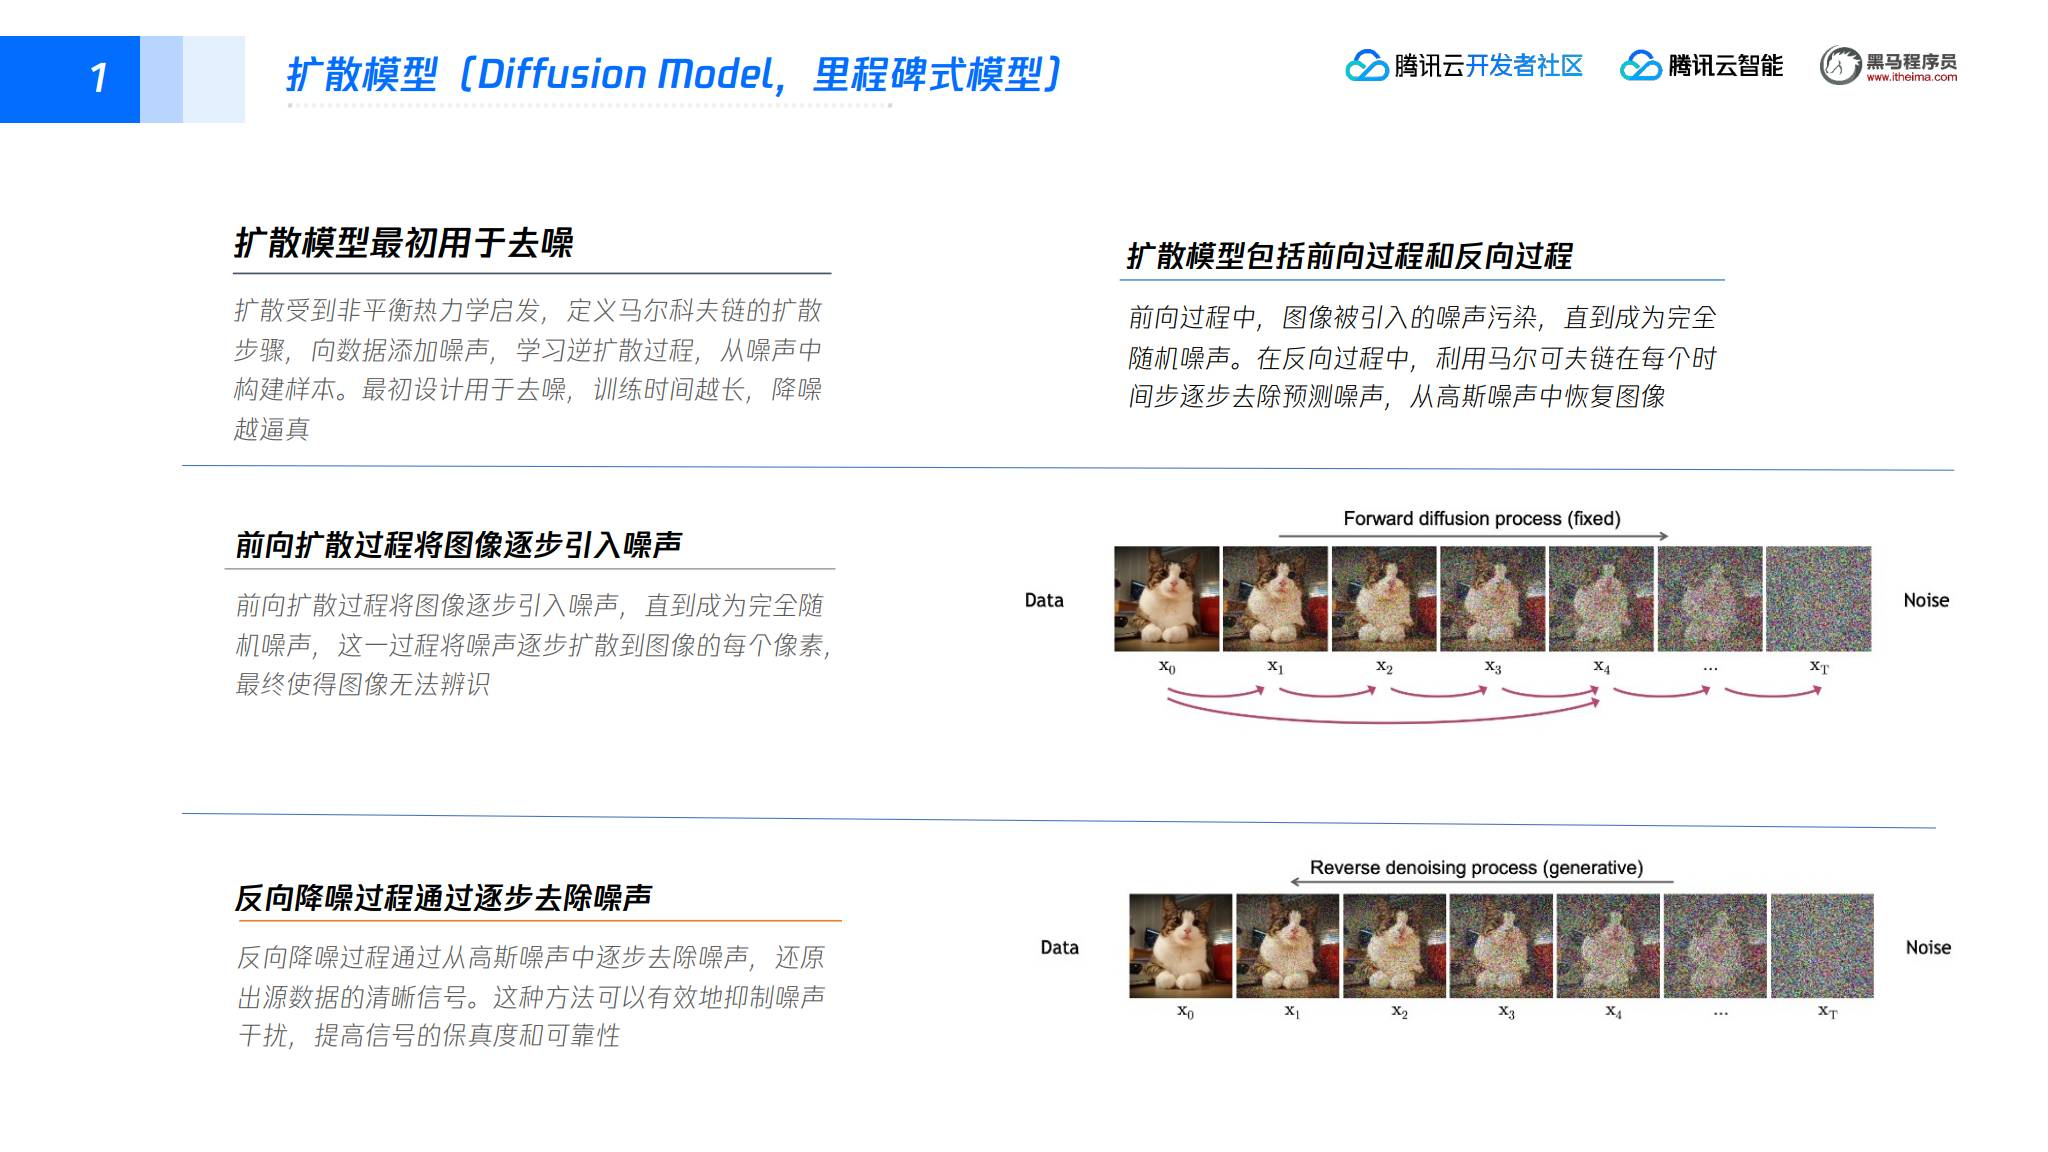

扩散模型的一个关键直觉是：前向过程把复杂数据逐步变成容易处理的随机噪声，反向过程再学习如何沿相反方向恢复数据。模型训练得越充分，反向去噪得到的图像通常越逼真。

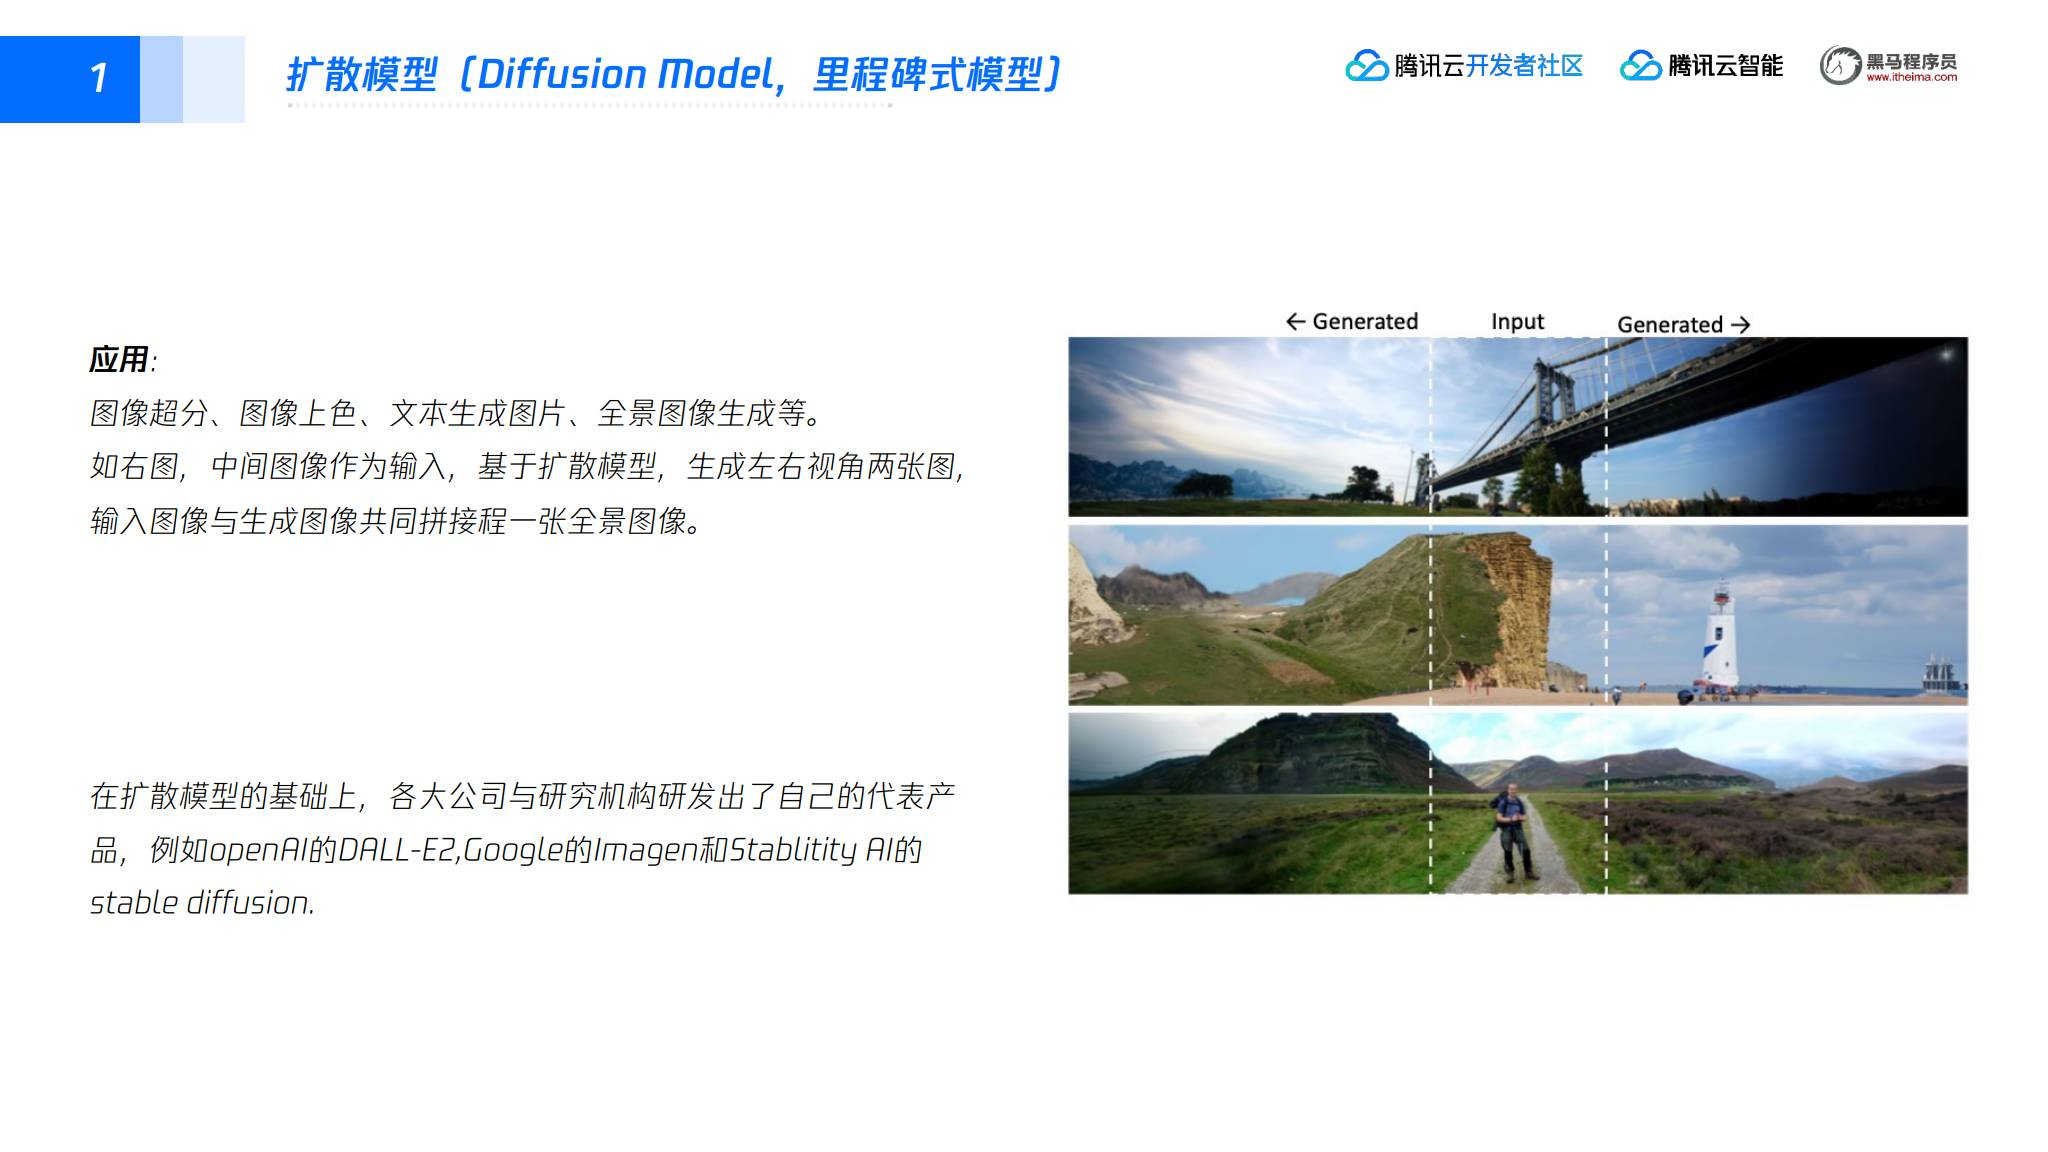

讲义列举了扩散模型的应用：图像超分、图像上色、文本生成图片和全景图像生成。例如以中间图像为输入，生成左右两个视角，再与输入图像拼接形成全景图像。

在扩散模型基础上出现了多个代表性系统，包括 OpenAI 的 DALL·E 2、Google 的 Imagen，以及 Stability AI 的 Stable Diffusion。

## 五、CLIP：图文对齐的跨模态基础模型

CLIP 由 OpenAI 于 2021 年发布，是一种跨模态预训练大模型。它采用双塔模型和对比学习，从互联网收集约 4 亿对图文数据进行训练。

CLIP 本身不能直接用来生成图像，但为图像生成提供了重要的文本—图像对齐能力。它要学习的关系是：给定一句文本，匹配与文本内容相符的图片；给定一张图片，匹配与图片相符的文本。

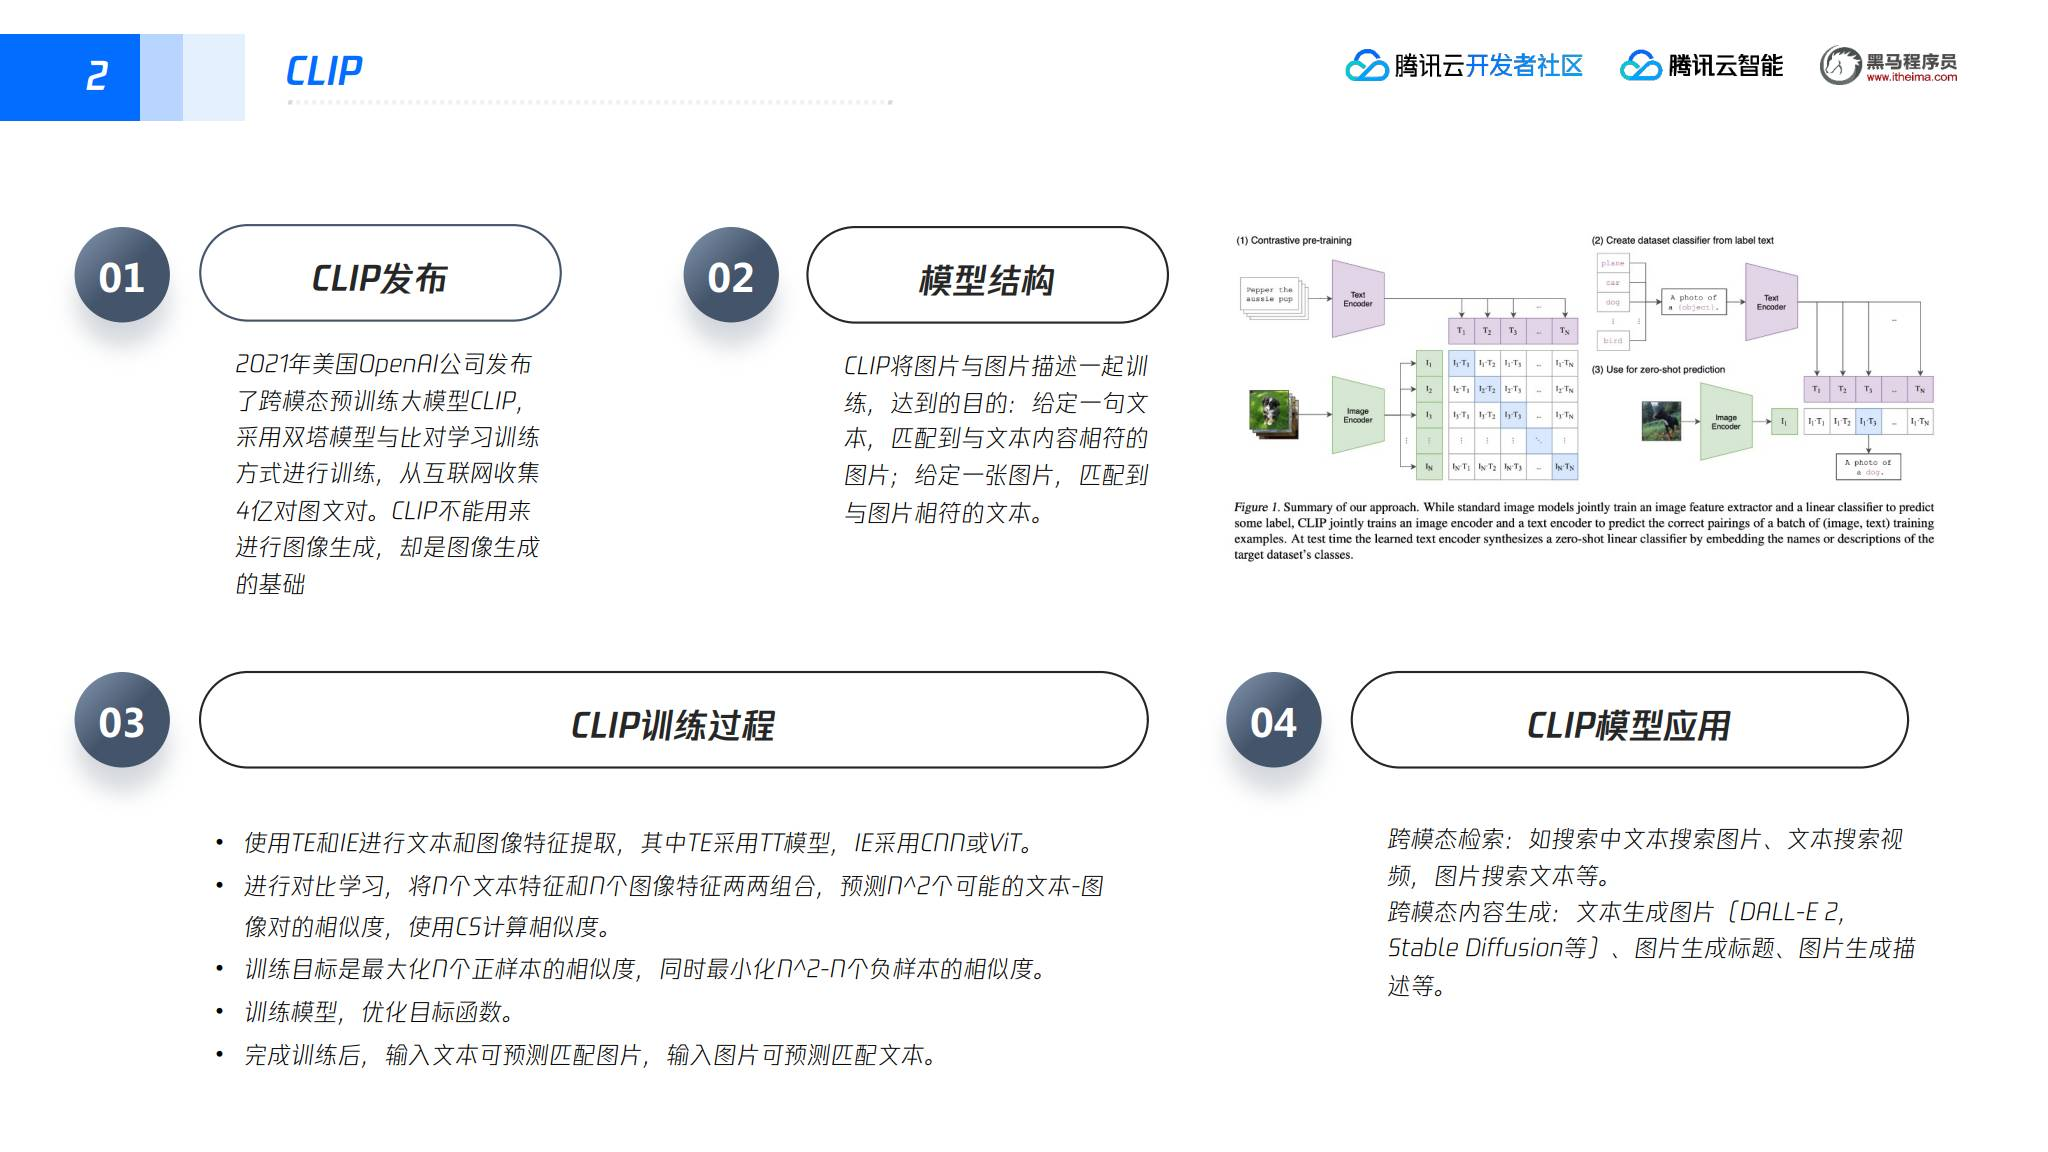

### CLIP 的训练流程

1. 使用文本编码器（TE）和图像编码器（IE）分别提取文本和图像特征；讲义中提到，文本编码器可采用 Transformer，图像编码器可采用 CNN 或 ViT。
2. 对一个批次中的 N 个文本特征和 N 个图像特征进行两两组合，得到 N² 个可能的文本—图像对。
3. 计算每一对文本特征和图像特征的相似度。
4. 最大化 N 个正样本对的相似度，同时最小化 N²−N 个负样本对的相似度。

训练完成后，CLIP 可以用于跨模态检索，例如文本搜图片、文本搜视频和图片搜文本；也可以作为跨模态内容生成系统中的图文对齐模块，支持文本生成图片、图片生成标题和图片生成描述等任务。

## 六、基于扩散模型的代表性系统

### 1. DALL·E

DALL·E 由 OpenAI 发布，并在 OpenAI 网站向公众开放。讲义介绍其提供数量有限的免费图像额度，也可以额外购买图像服务。它属于文本到图像的代表性系统，可以根据文本描述生成对应图像。

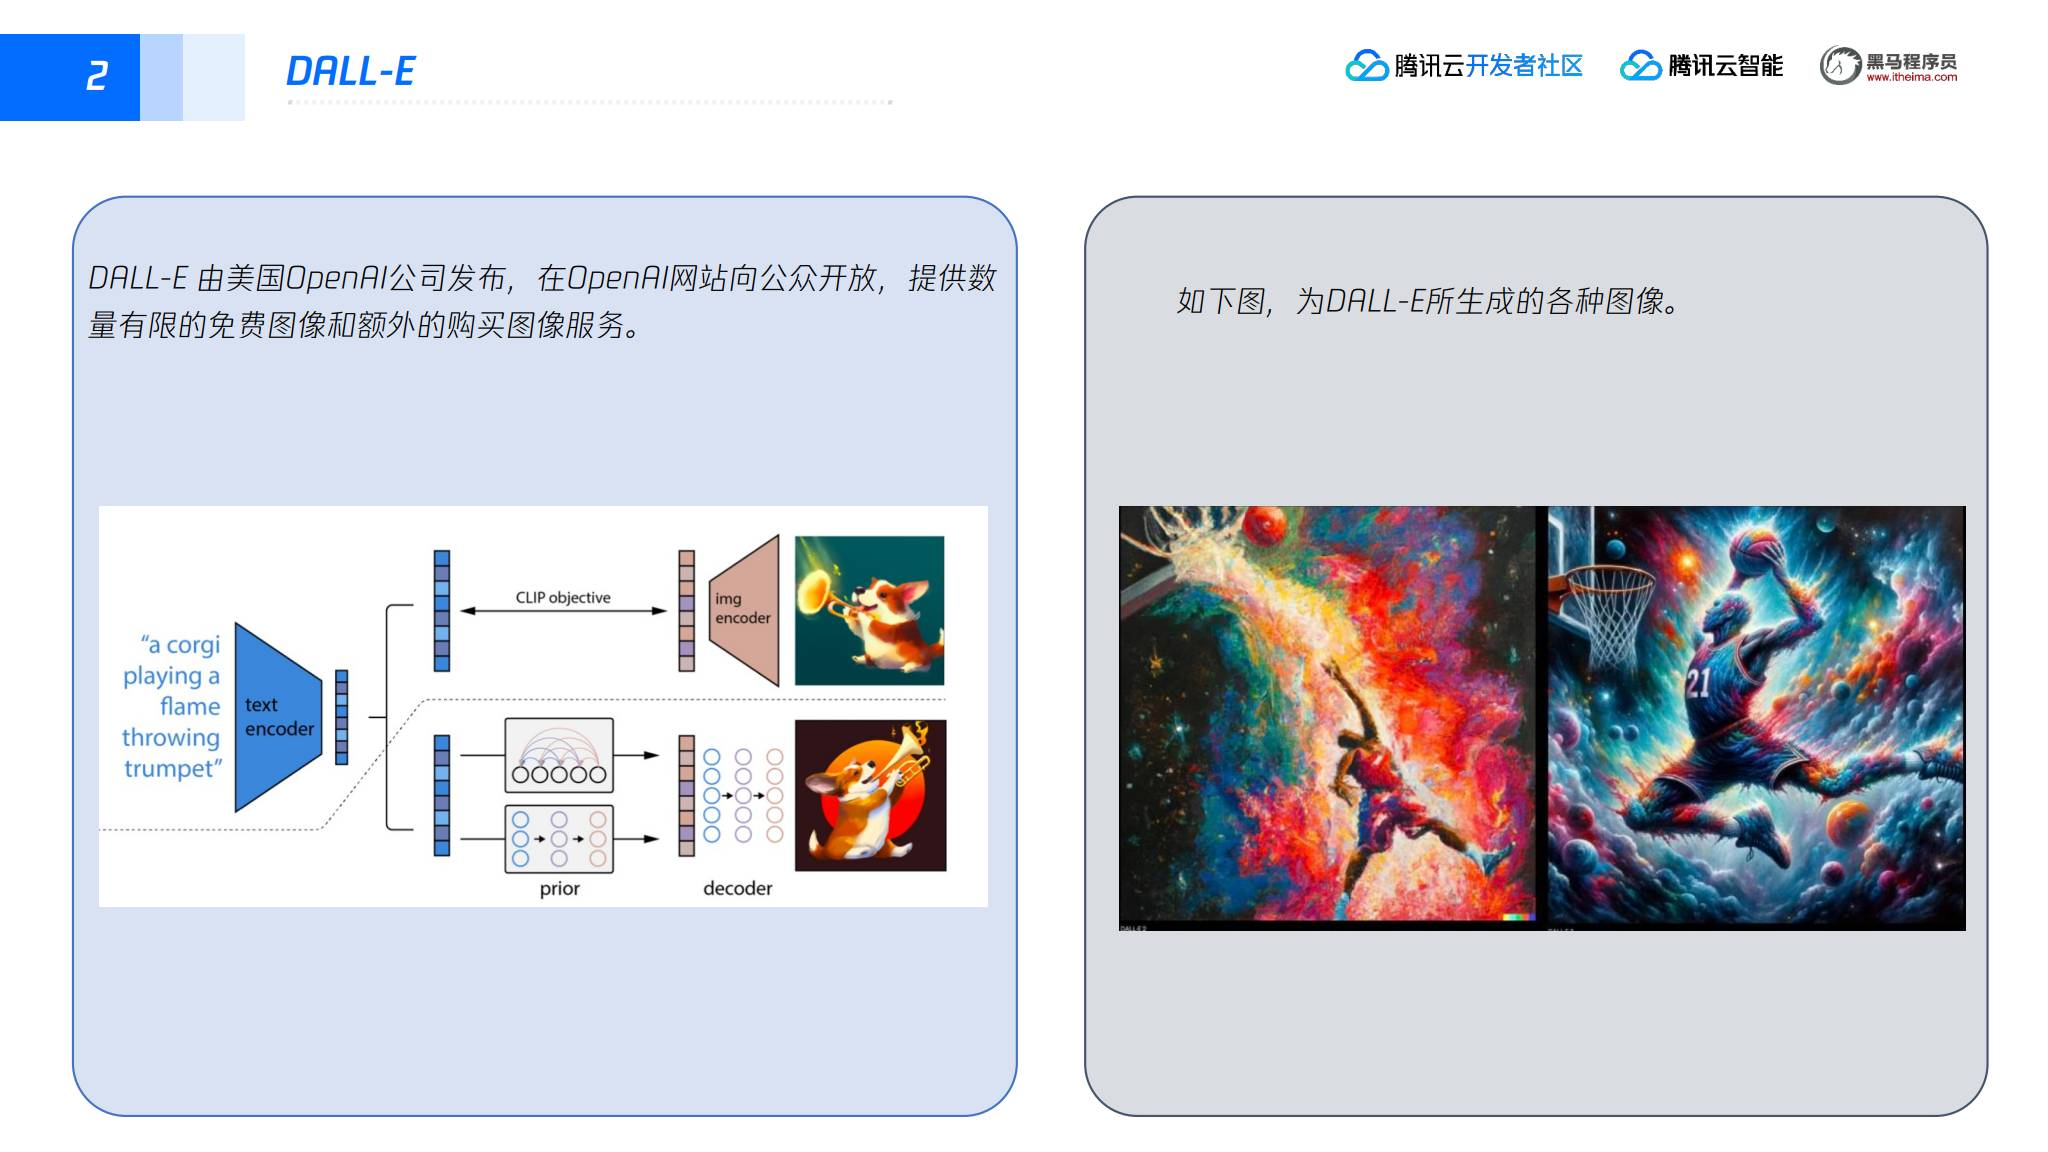

### 2. Imagen

Imagen 是 Google 于 2022 年 5 月发布的文本到图像扩散模型。讲义说明该模型当时不对外开放，用户通过输入描述性文本生成与文本匹配的图像。

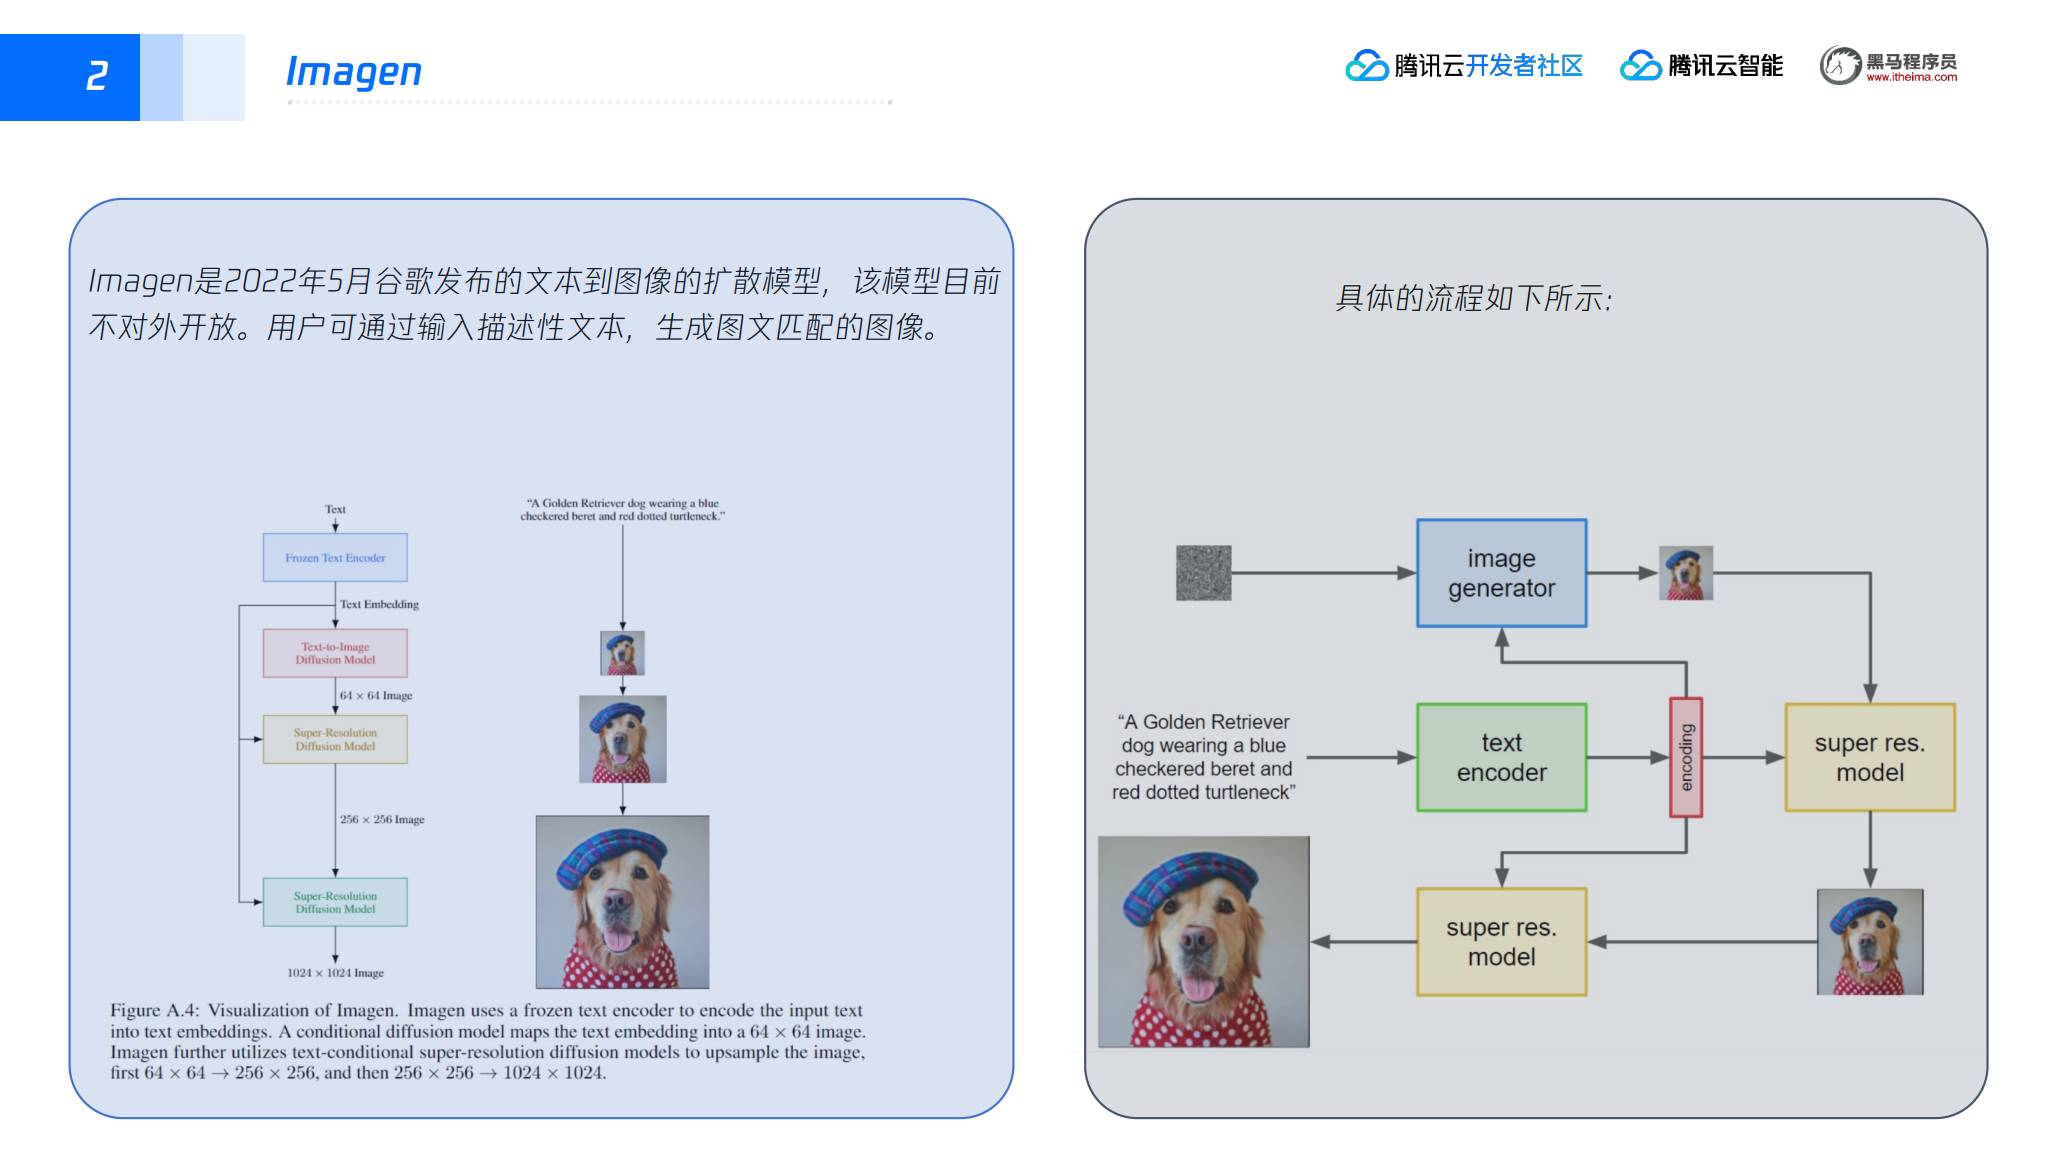

### 3. Stable Diffusion

Stable Diffusion 是由 Stability AI、CompVis 团队和 RunwayML 共同开源的文本到图像生成器。讲义将其定位为 AI 图像生成发展的里程碑，特点包括：

- 开源、免费，便于研究和应用；
- 根据 prompt 提示语生成图像，内容契合度和作画质量较高；
- 训练成本高，讲义提到其最初使用约 4000 台 A100 显卡训练。

讲义给出的提示语示例是“郊区街区一栋房子的照片，灯光明亮的超现实主义艺术，高度细致 8K”，模型会根据提示中的主体、场景和风格生成图像。

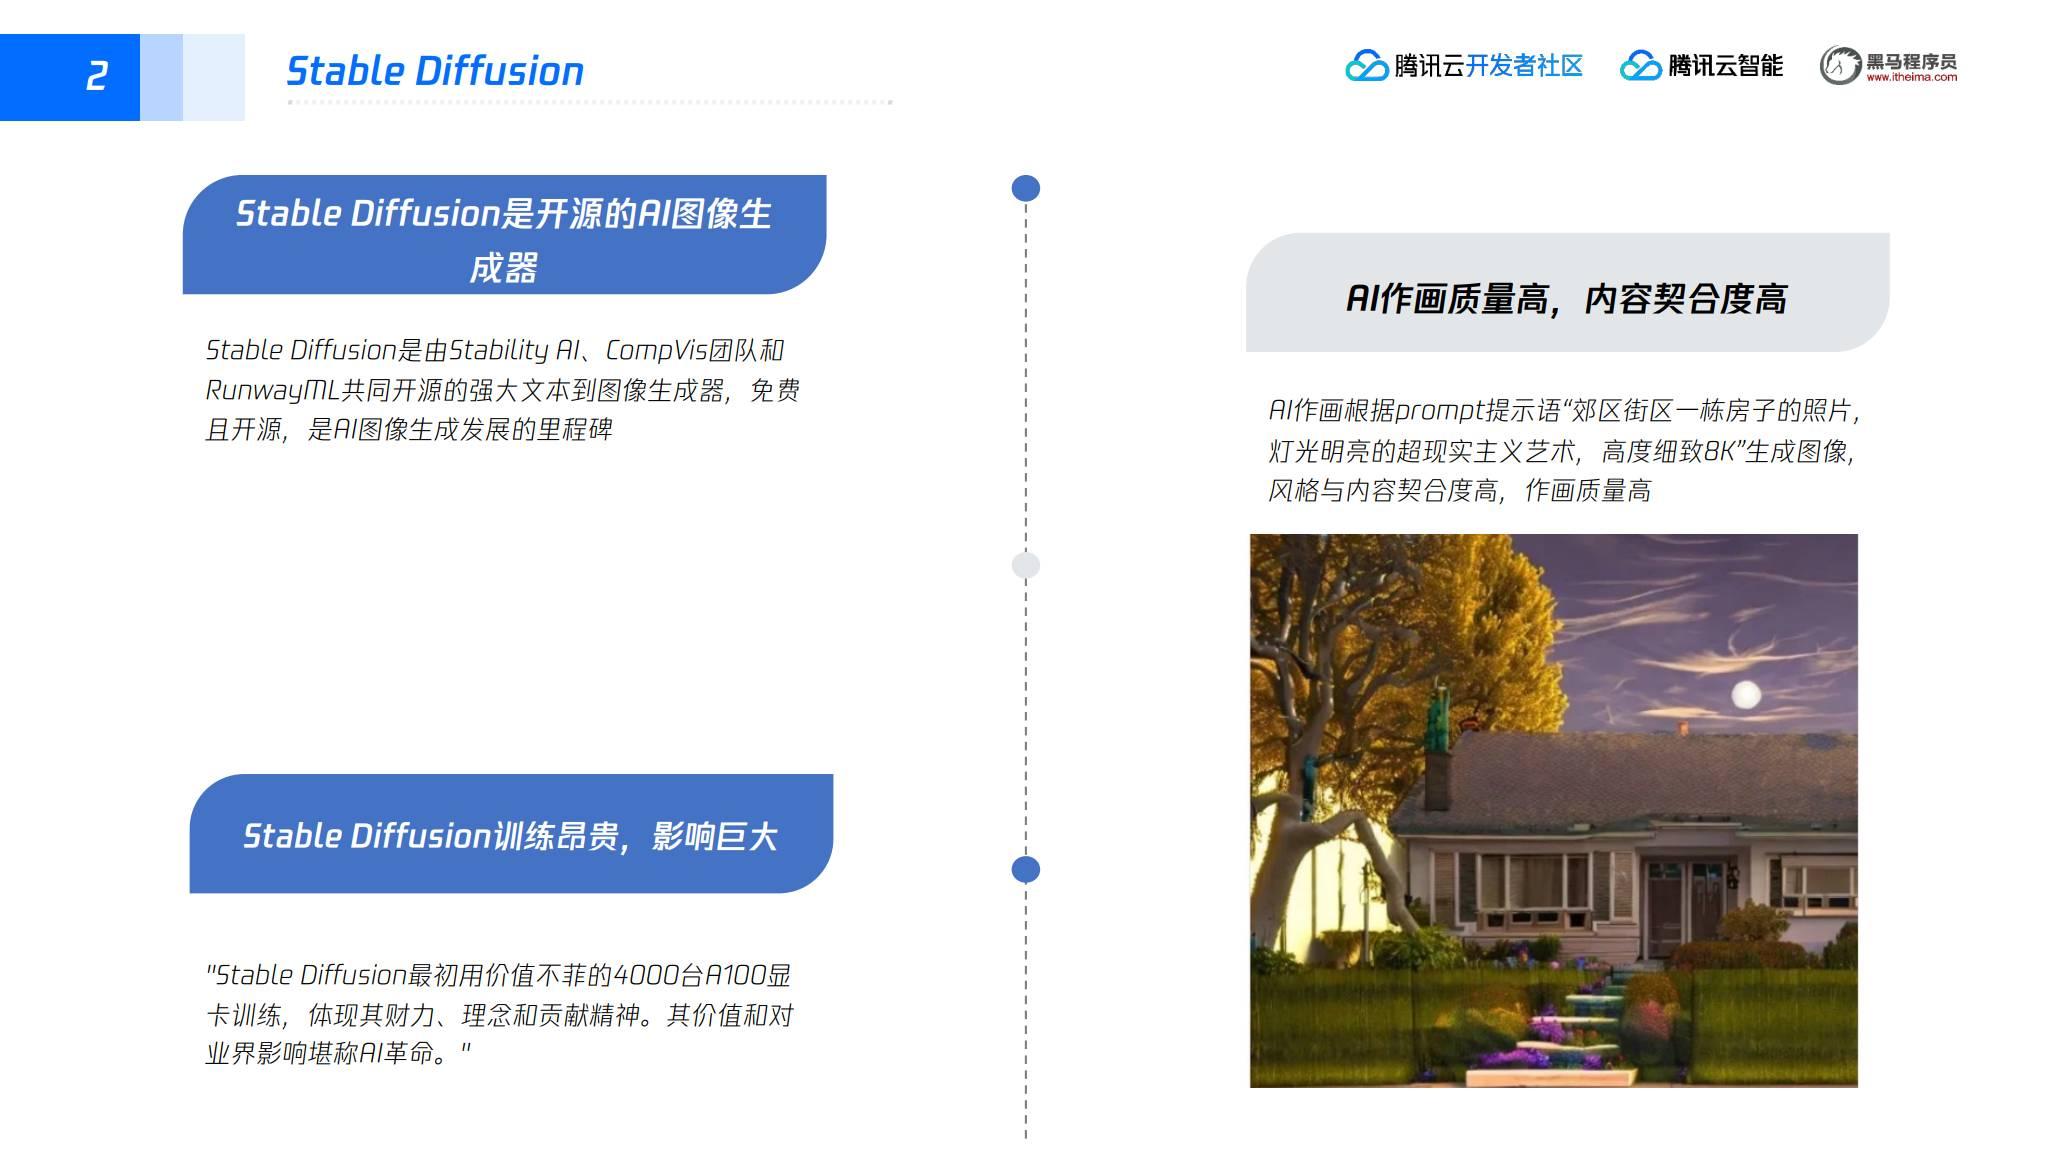

## 七、本篇要点

1. VAE 通过编码器、潜在空间采样和解码器完成生成；GAN 通过生成器与判别器的对抗学习生成数据。
2. 扩散模型先把图像逐步加噪，再学习逐步去噪，是当前图像生成系统的重要基础。
3. CLIP 负责学习文本和图像之间的对应关系，不能直接生成图像，但可以为文本—图像对齐和跨模态生成提供基础。
4. DALL·E、Imagen 和 Stable Diffusion 都是基于扩散模型发展的代表性文本到图像系统。